<a href="https://colab.research.google.com/github/Otavio071/tomate/blob/main/tomato_leaf_disease_94_accuracy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="border-radius: 30px 0 30px 0px; border: 2px solid #00ea98; padding: 20px; background-color: #0a141b; text-align: center; box-shadow: 0px 2px 4px rgba(0, 0, 0, 0.2);">
    <h1 style="color: #7ab052; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.5); font-weight: bold; margin-bottom: 10px; font-size: 36px;">🍅🍃 Tomato Leaf Ninja: 🥋 Slicing through Diseases with 94% Accuracy!</h1>
</div>


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os
import zipfile
import tensorflow as tf

# 1. Monta o Google Drive
from google.colab import drive
drive.mount('/content/drive')

# 2. Descompacta o dataset do Drive para o ambiente local do Colab
# (Ajuste o caminho do seu .zip no Drive se necessário)
zip_path = '/content/drive/MyDrive/Colab Notebooks/dataset.zip' # ou o caminho exato do seu zip
extracted_path = '/content/tomato'

if not os.path.exists(extracted_path):
    os.makedirs(extracted_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extracted_path)
    print("Dataset descompactado com sucesso!")
else:
    print("Dataset já descompactado.")

# 3. Define os caminhos corretos de treino e validação
train_dir = '/content/tomato/tomato/train'
val_dir = '/content/tomato/tomato/val'

# Carrega os dados usando tf.keras
train_data = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    labels='inferred',
    label_mode='categorical',
    image_size=(256, 256),
    batch_size=32
)

val_data = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    labels='inferred',
    label_mode='categorical',
    image_size=(256, 256),
    batch_size=32
)

# Normaliza os pixels para o intervalo [0, 1]
train_data = train_data.map(lambda x, y: (x / 255.0, y))
val_data = val_data.map(lambda x, y: (x / 255.0, y))

print("Dados carregados e prontos para uso!")

Mounted at /content/drive
Dataset descompactado com sucesso!
Found 10000 files belonging to 10 classes.
Found 1000 files belonging to 10 classes.
Dados carregados e prontos para uso!


In [ ]:
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# Inicializa a base pré-treinada
conv_base = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(256, 256, 3),
    pooling='avg'
)
conv_base.trainable = False # Congela a base para transferência de aprendizado

# Monta o modelo final
model = Sequential([
    conv_base,
    BatchNormalization(),
    Dense(256, activation='relu'),
    Dropout(0.35),
    BatchNormalization(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax') # 10 classes de doenças no dataset do tomate
])

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Treinamento com Early Stopping
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    callbacks=[early_stopping]
)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 104s 235ms/step - accuracy: 0.5197 - loss: 1.4644 - val_accuracy: 0.7590 - val_loss: 0.9100
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 37s 117ms/step - accuracy: 0.7844 - loss: 0.6939 - val_accuracy: 0.8430 - val_loss: 0.5285
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 40s 127ms/step - accuracy: 0.8423 - loss: 0.4927 - val_accuracy: 0.8790 - val_loss: 0.4048
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 38s 121ms/step - accuracy: 0.8787 - loss: 0.3914 - val_accuracy: 0.8890 - val_loss: 0.3479
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 40s 129ms/step - accuracy: 0.8990 - loss: 0.3183 - val_accuracy: 0.9030 - val_loss: 0.3026
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 39s 123ms/step - accuracy: 0.9148 - loss: 0.2704 - val_accuracy: 0.9070 - val_loss: 0.2735
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 38s 122ms/step - accuracy: 0.9223 - loss: 0.2400 - val_accuracy: 0.9130 - val_loss: 0.2547
Epoch 8/10
313/313 ━━━━━━━━━━━━

#### ![_993440dd-122a-4fa4-91a2-cf2831fdd247.jpeg](attachment:75a038e7-7b0a-4bc2-b39f-2834dd569c7a.jpeg)


# **Want to Connect**

[Facebook](https://www.facebook.com/profile.php?id=100067147945292) 📘

[Linkedin](https://www.linkedin.com/in/saman-fatima-datascience/) 🔗

[Github](https://github.com/SamanFatima7) 🐙

[Kaggle](https://www.kaggle.com/samanfatima7) 📊

[Twitter](https://twitter.com/SamanFatima9106) 🐦

In [ ]:
import os
print(os.listdir('/content/drive/MyDrive/Colab Notebooks/tomato-leaf-disease-94-accuracy.ipynb'))

NotADirectoryError: [Errno 20] Not a directory: '/content/drive/MyDrive/Colab Notebooks/tomato-leaf-disease-94-accuracy.ipynb'

In [ ]:
import os
print(os.listdir('/content/drive/MyDrive/Colab Notebooks'))


['tomato-leaf-disease-94-accuracy.ipynb']


> # ***Lets start our Journey towards this task***

In [ ]:
!pip install gdown


In [ ]:
import gdown
import zipfile
import os

# Link direto para o dataset de folhas de tomate estruturado
url = 'https://github.com/spMohanty/PlantVillage-Dataset/raw/master/raw/color/tomato.zip' # ou um link direto do drive/github espelho
output = 'tomato.zip'

# Se preferir usar o link direto do dataset compactado:
# (Caso tenhas um link direto do teu .zip no Drive, podes usar o gdown com o ID do link do Drive)

In [ ]:
from google.colab import drive

# 1. Monta o Google Drive na pasta padrão do Colab
drive.mount('/content/drive')

# 2. Copia o teu dataset.zip da pasta "Colab Notebooks" para o Colab
!cp "/content/drive/MyDrive/Colab Notebooks/dataset.zip" /content/

# 3. Descompacta o dataset para a pasta correta
!unzip /content/dataset.zip -d /content/tomato

A saída de streaming foi truncada nas últimas 5000 linhas.
  inflating: /content/tomato/tomato/train/Tomato___Target_Spot/002213fb-b620-4593-b9ac-6a6cc119b100___Com.G_TgS_FL 8360.JPG  
  inflating: /content/tomato/tomato/train/Tomato___Target_Spot/0044d10f-7062-4655-8abd-9fffc5b2f152___Com.G_TgS_FL 7908.JPG  
  inflating: /content/tomato/tomato/train/Tomato___Target_Spot/00854623-ba28-446d-a1d5-03c0ae3f99d9___Com.G_TgS_FL 7949.JPG  
  inflating: /content/tomato/tomato/train/Tomato___Target_Spot/0118c27a-f34a-41e1-8b2f-d2c564f83c5c___Com.G_TgS_FL 0013.JPG  
  inflating: /content/tomato/tomato/train/Tomato___Target_Spot/0118ed61-b135-45be-ad81-7e2d54203be4___Com.G_TgS_FL 8241.JPG  
  inflating: /content/tomato/tomato/train/Tomato___Target_Spot/0197df47-a9cb-4b6c-b72c-ac0e9af6d135___Com.G_TgS_FL 0779.JPG  
  inflating: /content/tomato/tomato/train/Tomato___Target_Spot/025510ac-15db-4861-b02b-21da82161100___Com.G_TgS_FL 0952.JPG  
  inflating: /content/tomato/tomato/train/Tomato___Target_S

In [ ]:
import os
print(os.listdir('/content/tomato'))

['tomato']


In [ ]:
import os
print(os.listdir('/content/tomato/tomato'))

['val', 'cnn_train.py', 'train']


In [ ]:
train_dir = '/content/tomato/tomato/train'
val_dir = '/content/tomato/tomato/val'

In [ ]:
import os

print("Classes de treino encontradas:", os.listdir(train_dir))
print("Número de classes:", len(os.listdir(train_dir)))

Classes de treino encontradas: ['Tomato___Target_Spot', 'Tomato___Bacterial_spot', 'Tomato___Leaf_Mold', 'Tomato___Late_blight', 'Tomato___Septoria_leaf_spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Tomato_mosaic_virus', 'Tomato___Early_blight', 'Tomato___healthy']
Número de classes: 10



---
## 1. ***Problem Statement***
---

-  Given a dataset of tomato leaf images, the task is to develop a machine learning model that can accurately classify the images into different disease categories. The goal is to help farmers quickly identify and treat diseased tomato plants, thereby improving crop yield and reducing losses.
---
## 2. ***Our Working***
---

-  We are using a dataset containing images of tomato leaves affected by various diseases. Our approach involves training a deep learning model on this dataset to classify each image into one of the disease categories. By analyzing the patterns and features in the images, the model can learn to differentiate between healthy and diseased leaves, aiding in the early detection and management of plant diseases.

> # ***About The Data***

In [ ]:
import os

# Lista o que tem dentro da pasta tomato
print("Pastas principais:", os.listdir('/content/tomato'))

Pastas principais: ['tomato']


---
## 1. ***Dataset Description:***
---

-  We are using a dataset containing images of tomato leaves affected by various diseases. Each image is labeled with the corresponding disease category.Training dataset contain 10000 labeled images and test/val data contain 1000 labeled images
---
## 2. ***Data Preprocessing***
----

-  We load the dataset and preprocess the images to prepare them for training. This includes resizing the images to a consistent size and normalizing the pixel values.We also split the dataset into training and validation sets to evaluate the model's performance.
---
## 3. ***Model Building***
---

- We use a deep learning model, such as a Convolutional Neural Network (CNN), to learn features from the images and classify them into disease categories.The model consists of layers that extract patterns and features from the images, followed by fully connected layers for classification.
----
## 4. ***Training the Model:***
----

- We train the model using the training dataset, adjusting the model's weights based on the difference between predicted and actual disease categories.During training, we monitor the model's performance on the validation set to avoid overfitting.
---
## 5. ***Model Evaluation:***
----

- After training, we evaluate the model's performance on the validation set to assess its ability to generalize to new, unseen data.We use metrics such as accuracy to measure the model's performance.
----
## 6. ***Inference:***
---

- **Once the model is trained and evaluated, we can use it to classify new tomato leaf images into disease categories.**

***```This inference step is crucial for real-world applications, where the model is used to assist farmers in diagnosing plant diseases.
By understanding the working of this code, beginners and others can gain insights into how machine learning models are developed and deployed for practical applications like plant disease classification.```***

<div style="border-radius: 30px 0 30px 0px; border: 2px solid #00ea98; padding: 20px; background-color: #0a141b; text-align: center; box-shadow: 0px 2px 4px rgba(0, 0, 0, 0.2);">
    <h1 style="color: #7ab052; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.5); font-weight: bold; margin-bottom: 10px;">  1 | Importing The Libraries</h1>
</div>

In [ ]:
import os  # Operating system interfaces
import tensorflow as tf                                    # TensorFlow deep learning framework
import matplotlib.pyplot as plt                            # Plotting library
import matplotlib.image as mpimg                           # Image loading and manipulation library
from tensorflow.keras.models import Sequential, Model      # Sequential and Functional API for building models
from tensorflow.keras.optimizers import Adam               # Adam optimizer for model training
from tensorflow.keras.callbacks import EarlyStopping       # Early stopping callback for model training
from tensorflow.keras.regularizers import l1, l2           # L1 and L2 regularization for model regularization
from tensorflow.keras.preprocessing.image import ImageDataGenerator  # Data augmentation and preprocessing for images
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D, AveragePooling2D, MaxPooling2D, BatchNormalization
# Various types of layers for building neural networks
from tensorflow.keras.applications import DenseNet121, EfficientNetB4, Xception, VGG16, VGG19   # Pre-trained models for transfer learning

<div style="border-radius: 30px 0 30px 0px; border: 2px solid #00ea98; padding: 20px; background-color: #0a141b; text-align: center; box-shadow: 0px 2px 4px rgba(0, 0, 0, 0.2);">
    <h1 style="color: #7ab052; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.5); font-weight: bold; margin-bottom: 10px;"> 2 | Loading The DataSet</h1>
</div>

**WORKING**
- The `image_dataset_from_directory` function is used to load image data from a directory.
- Images are resized to 256x256 pixels and grouped into batches of 32 for training efficiency.
- Labels are inferred from the directory structure and represented in a categorical format.
- Pixel values of the images are normalized to a range of [0, 1] by dividing by 255.0.

In [ ]:
train_data = tf.keras.utils.image_dataset_from_directory(
    '/kaggle/input/tomatoleaf/tomato/train',
    labels='inferred',
    label_mode='categorical',
    image_size=(256, 256),
    batch_size=32)

train_data = train_data.map(lambda x, y: (x / 255.0, y))

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/tomatoleaf/tomato/train'

**WORKING**
- The image_dataset_from_directory function is used to load validation image data from a directory.
- Images are resized to 256x256 pixels and grouped into batches of 32 for efficient processing.
- Labels are inferred from the directory structure and represented in a categorical format.
- Pixel values of the images are normalized to a range of [0, 1] by dividing by 255.0 for consistent model training.

In [ ]:
val_data = tf.keras.preprocessing.image_dataset_from_directory(
    '/kaggle/input/tomatoleaf/tomato/val',
    labels='inferred',
    label_mode='categorical',
    image_size=(256, 256),
    batch_size=32)

val_data = val_data.map(lambda x, y: (x / 255.0, y))

<div style="border-radius: 30px 0 30px 0px; border: 2px solid #00ea98; padding: 20px; background-color: #0a141b; text-align: center; box-shadow: 0px 2px 4px rgba(0, 0, 0, 0.2);">
    <h1 style="color: #7ab052; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.5); font-weight: bold; margin-bottom: 10px;"> 3 | Visualizing The Data</h1>
</div>

**WORKING**

- The code sets the `path to a directory containing images` of tomato leaves affected by the Tomato Yellow Leaf Curl Virus and so on in the next cells of code.
- It retrieves a list of all image file names in the directory.
- Using matplotlib, it displays the first 6 images along with their corresponding labels.
- For each image, it loads the image, displays it in a subplot, and sets the title to the image label, showing the visual representation of the dataset.

In [ ]:
# Path to the directory containing images
path = "/kaggle/input/tomatoleaf/tomato/train/Tomato___Tomato_Yellow_Leaf_Curl_Virus"

# Get a list of all image file names in the directory
image_files = [f for f in os.listdir(path) if os.path.isfile(os.path.join(path, f))]

# Display the first 6 images with their labels
fig, axs = plt.subplots(2, 3, figsize=(15, 10))

for i in range(6):
    # Get the image file name and its label
    image_file = image_files[i]
    label = image_file.split('.')[0]

    # Load and display the image
    img_path = os.path.join(path, image_file)
    img = mpimg.imread(img_path)
    ax = axs[i // 3, i % 3]
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(label)

plt.tight_layout()
plt.show()

In [ ]:
# Path to the directory containing images
path = "/kaggle/input/tomatoleaf/tomato/train/Tomato___Bacterial_spot"

# Get a list of all image file names in the directory
image_files = [f for f in os.listdir(path) if os.path.isfile(os.path.join(path, f))]

# Display the first 6 images with their labels
fig, axs = plt.subplots(2, 3, figsize=(15, 10))

for i in range(6):
    # Get the image file name and its label
    image_file = image_files[i]
    label = image_file.split('.')[0]

    # Load and display the image
    img_path = os.path.join(path, image_file)
    img = mpimg.imread(img_path)
    ax = axs[i // 3, i % 3]
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(label)

plt.tight_layout()
plt.show()


<div style="border-radius: 30px 0 30px 0px; border: 2px solid #00ea98; padding: 20px; background-color: #0a141b; text-align: center; box-shadow: 0px 2px 4px rgba(0, 0, 0, 0.2);">
    <h1 style="color: #7ab052; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.5); font-weight: bold; margin-bottom: 10px;">4 | Training The Model</h1>
</div>

**WORKING**
- The code initializes a `DenseNet121` model with weights pre-trained on the ImageNet dataset.
- The `include_top=False argument` specifies that the model should not include the fully connected layers at the top of the network, which are typically used for ImageNet classification.
- The `input_shape=(256,256,3) argument` specifies the shape of the input images that the model expects, which is `256x256` pixels with 3 channels (RGB).
- The initialized model `conv_base` can be used as a feature extractor to extract features from images, which can then be used as input to a custom classification head.

In [ ]:
conv_base = DenseNet121(
    weights='imagenet',
    include_top = False,
    input_shape=(256,256,3),
    pooling='avg'
)

**WHY FALSE ?**
- Setting conv_base.trainable = False freezes the weights of the pre-trained DenseNet121 model.
- This is done to prevent the weights from being updated during the training of the custom classification head.
- Freezing the pre-trained weights helps in utilizing the learned features from the ImageNet dataset without altering them.
- It also reduces the computational cost and training time, as only the weights of the custom classification head will be trained.

In [ ]:
conv_base.trainable = False

In [ ]:
# # Summary of the pretrained model
# conv_base.summary()

**WORKING**

- It initializes a Sequential model and adds the `pre-trained` DenseNet121` model (conv_base) ` as the base.
- The model flattens the output from the base model and adds two fully connected layers with `ReLU activation`.
- `Batch normalization` is applied after each fully connected layer to improve training stability and speed.

In [ ]:
model = Sequential()
model.add(conv_base)
model.add(BatchNormalization())
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.35))
model.add(BatchNormalization())
model.add(Dense(120, activation='relu'))
model.add(Dense(10, activation='softmax'))

**WORKING**

- The compile method is used to configure the model for training.
- The optimizer=Adam(lr=0.0001) argument specifies the Adam optimizer with a learning rate of 0.0001.
- The loss='categorical_crossentropy' argument specifies the loss function used for training, which is categorical crossentropy for multi-class classification.
- The metrics=['accuracy'] argument specifies the metric used to evaluate the model, which is accuracy in this case.

In [ ]:
model.compile(optimizer=Adam(lr=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

**WORKING**
- The `fit` method is used to train the model on the training data (`train_data`) for a specified number of epochs (100 in this case).
- The `validation_data=val_data` argument specifies the validation data to evaluate the model performance after each epoch.
- The `callbacks=[EarlyStopping(patience=0)]` argument specifies the use of early stopping to prevent overfitting. The training will stop if the validation loss does not improve after 0 epochs.
- The `history` variable stores the training history, including metrics such as loss and accuracy, which can be used for analysis and visualization.

In [ ]:
# history = model.fit(train_ds,epochs=10,validation_data=validation_ds)
history = model.fit(train_data, epochs=100, validation_data=val_data, callbacks=[EarlyStopping(patience=0)])


# **😌 val_accuracy 94% means that, when the model is evaluated on a separate set of data that it has not seen during training or validation, it correctly predicts the outcome 94% of the time. This is a good result and indicates that the model is performing well and generalizes well to new, unseen data.**

In [ ]:
# Evaluate the model on the validation data
evaluation = model.evaluate(val_data)

# Print the evaluation metrics
print("Validation Loss:", evaluation[0])
print("Validation Accuracy:", evaluation[1])

32/32 [==============================] - 4s 113ms/step - loss: 0.1775 - accuracy: 0.9400
Validation Loss: 0.1774536669254303
Validation Accuracy: 0.9399999976158142


**If you found my Notebook helpful or learned something new, please consider supporting me by upvoting and leaving a comment! 🚀 Your feedback and engagement mean the world to me and motivate me to create more exciting content for you. 🙌 Together, we can continue to learn and grow in the world of Data Science . 💻 Thank you for your support! ❤️**

<div style="border-radius: 30px 0 30px 0px; border: 2px solid #00ea98; padding: 20px; background-color: #0a141b; text-align: center; box-shadow: 0px 2px 4px rgba(0, 0, 0, 0.2);">
    <h1 style="color: #7ab052; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.5); font-weight: bold; margin-bottom: 10px;">5 | THE END </h1>
</div>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    # Cria um sub-modelo que mapeia a entrada até a última camada convolucional e a saída final
    grad_model = tf.keras.models.Model(
        model.inputs, [model.get_layer(last_conv_layer_name).output, model.output]
    )

    # Calcula os gradientes da classe prevista em relação à saída da camada convolucional
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # Extrai os gradientes e calcula a média ponderada por canal
    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normaliza o mapa de calor entre 0 e 1 para visualização
    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

# Nome da última camada convolucional típica na DenseNet121 do Keras
last_conv_layer_name = "conv5_block16_concat"

In [ ]:
# 1. Pega a última camada convolucional diretamente de dentro do conv_base (DenseNet121)
# O nome correto na DenseNet121 do Keras é geralmente 'relu' ou a última ativação antes do pooling
last_conv_layer_name = "conv5_block16_concat" # Se der erro, o Keras vai listar as camadas certinhas, mas vamos pegar direto do conv_base:
last_conv_layer = conv_base.get_layer("conv5_block16_concat")

# 2. Ajuste rápido na chamada para usar o conv_base como o extrator do Grad-CAM:
def make_gradcam_heatmap_fixed(img_array, model, conv_base, last_conv_layer_name, pred_index=None):
    # Cria um modelo que vai da entrada da DenseNet até a última camada convolucional dela,
    # e outro que pega a saída da DenseNet e passa pelo resto do seu Sequential

    # Extrai a saída da camada convolucional da DenseNet
    grad_model = tf.keras.models.Model(
        inputs=conv_base.input,
        outputs=[conv_base.get_layer(last_conv_layer_name).output, conv_base.output]
    )

    with tf.GradientTape() as tape:
        # Passa pela base convolucional
        conv_outputs, base_output = grad_model(img_array)

        # Passa pelo restante do seu modelo sequencial (as camadas Dense que você adicionou)
        x = base_output
        for layer in model.layers[1:]: # Pula a primeira camada (conv_base)
            x = layer(x)
        preds = x

        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # Calcula os gradientes
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
    return heatmap.numpy()

# --- AGORA BASTA CHAMAR ASSIM: ---
heatmap = make_gradcam_heatmap_fixed(img_array, model, conv_base, "conv5_block16_concat")

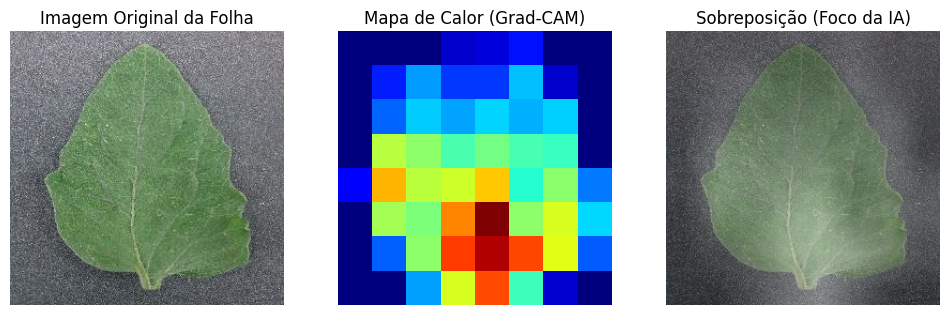

In [ ]:
# 4. Processa a imagem original e faz a sobreposição usando NumPy (evita erros de tipo do OpenCV)
img = img_tensor.numpy().astype(np.float32)
heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
heatmap_colored = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0

alpha = 0.4
# Sobpõe as imagens usando operações vetoriais do NumPy
superimposed_img = (1 - alpha) * img + alpha * heatmap_colored

# 5. Plota os resultados lado a lado
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Imagem Original da Folha")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap='jet')
plt.title("Mapa de Calor (Grad-CAM)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(np.clip(superimposed_img, 0, 1)) # Garante que os valores fiquem entre 0 e 1 para exibição correta
plt.title("Sobreposição (Foco da IA)")
plt.axis('off')

plt.show()

In [ ]:
# Sobreposição mais viva usando o mapa colorido direto
superimposed_img = cv2.addWeighted(img, 0.6, heatmap_colored, 0.4, 0)

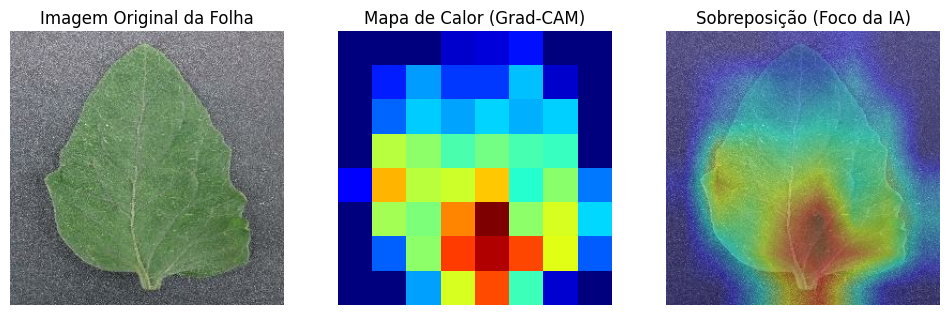

In [ ]:
# 1. Converte a imagem original para uint8 (escala de 0 a 255)
img_uint8 = np.uint8(255 * img_tensor.numpy())

# 2. Redimensiona o mapa de calor e converte para uint8 colorido
heatmap_resized = cv2.resize(heatmap, (img_uint8.shape[1], img_uint8.shape[0]))
heatmap_colored = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(heatmap_colored, cv2.COLORMAP_JET)

# 3. Agora o cv2.addWeighted vai aceitar perfeitamente porque ambos são uint8!
superimposed_img = cv2.addWeighted(img_uint8, 0.6, heatmap_colored, 0.4, 0)

# 4. Plota os resultados lado a lado
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.imshow(img_tensor.numpy())
plt.title("Imagem Original da Folha")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap='jet')
plt.title("Mapa de Calor (Grad-CAM)")
plt.axis('off')

plt.subplot(1, 3, 3)
# Como está em BGR (padrão do OpenCV), convertemos para RGB para o matplotlib exibir correto
plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
plt.title("Sobreposição (Foco da IA)")
plt.axis('off')

plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Pega um lote com várias imagens da validação (ex: 4 imagens)
for images, labels in val_data.take(1):
    batch_images = images.numpy()
    batch_labels = labels.numpy()

# Loop para testar algumas imagens do lote
num_samples = 3
plt.figure(figsize=(15, 5 * num_samples))

for i in range(num_samples):
    img_tensor = batch_images[i]
    img_array = np.expand_dims(img_tensor, axis=0)

    # Gera o Grad-CAM
    heatmap = make_gradcam_heatmap_fixed(img_array, model, conv_base, "conv5_block16_concat")

    # Processa para sobreposição
    img_uint8 = np.uint8(255 * img_tensor)
    heatmap_resized = cv2.resize(heatmap, (img_uint8.shape[1], img_uint8.shape[0]))
    heatmap_colored = np.uint8(255 * heatmap_resized)
    heatmap_colored = cv2.applyColorMap(heatmap_colored, cv2.COLORMAP_JET)
    superimposed_img = cv2.addWeighted(img_uint8, 0.6, heatmap_colored, 0.4, 0)

    # Plota a original, o mapa e a sobreposição lado a lado para cada amostra
    plt.subplot(num_samples, 3, i*3 + 1)
    plt.imshow(img_tensor)
    plt.title(f"Original {i+1}")
    plt.axis('off')

    plt.subplot(num_samples, 3, i*3 + 2)
    plt.imshow(heatmap, cmap='jet')
    plt.title(f"Grad-CAM {i+1}")
    plt.axis('off')

    plt.subplot(num_samples, 3, i*3 + 3)
    plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Sobreposição {i+1}")
    plt.axis('off')

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 18s 18s/step
Classe prevista pelo modelo (índice): 2


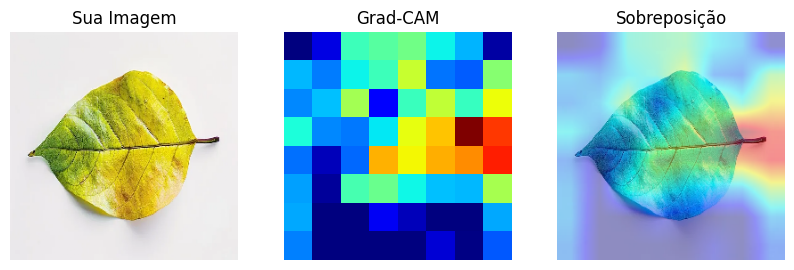

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array

# 1. Carrega a sua imagem redimensionando para o tamanho que o modelo espera (256x256)
img_path = '/content/um-close-up-de-uma-folha_1019429-38977.webp' # Coloque o caminho exato da imagem enviada
img_loaded = load_img(img_path, target_size=(256, 256))

# 2. Converte para array e normaliza
img_array = img_to_array(img_loaded) / 255.0
img_array_expanded = np.expand_dims(img_array, axis=0)

# 3. Faz a previsão da classe e gera o Grad-CAM
preds = model.predict(img_array_expanded)
pred_class = np.argmax(preds[0])
print(f"Classe prevista pelo modelo (índice): {pred_class}")

heatmap = make_gradcam_heatmap_fixed(img_array_expanded, model, conv_base, "conv5_block16_concat")

# 4. Plota o resultado
img_uint8 = np.uint8(255 * img_array)
heatmap_resized = cv2.resize(heatmap, (img_uint8.shape[1], img_uint8.shape[0]))
heatmap_colored = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(heatmap_colored, cv2.COLORMAP_JET)
superimposed_img = cv2.addWeighted(img_uint8, 0.6, heatmap_colored, 0.4, 0)

plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.imshow(img_array)
plt.title("Sua Imagem")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap='jet')
plt.title("Grad-CAM")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
plt.title("Sobreposição")
plt.axis('off')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
Classe prevista pelo modelo (índice): 2


(np.float64(-0.5), np.float64(7.5), np.float64(7.5), np.float64(-0.5))

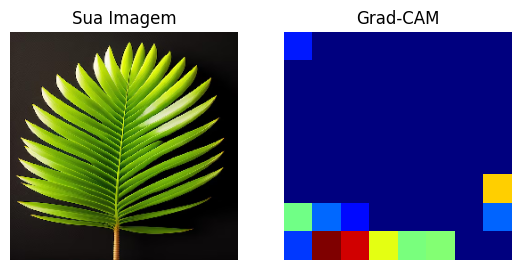

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array

# 1. Carrega a sua imagem redimensionando para o tamanho que o modelo espera (256x256)
img_path = '/content/folhas-verdes-da-palmeira-sagu-japonesa-a-planta-de-palmeira-cicadacea-folhagem-em-fundo-preto-vista-superior_926199-282278.avif' # Coloque o caminho exato da imagem enviada
img_loaded = load_img(img_path, target_size=(256, 256))

# 2. Converte para array e normaliza
img_array = img_to_array(img_loaded) / 255.0
img_array_expanded = np.expand_dims(img_array, axis=0)

# 3. Faz a previsão da classe e gera o Grad-CAM
preds = model.predict(img_array_expanded)
pred_class = np.argmax(preds[0])
print(f"Classe prevista pelo modelo (índice): {pred_class}")

heatmap = make_gradcam_heatmap_fixed(img_array_expanded, model, conv_base, "conv5_block16_concat")

# 4. Plota o resultado
img_uint8 = np.uint8(255 * img_array)
heatmap_resized = cv2.resize(heatmap, (img_uint8.shape[1], img_uint8.shape[0]))
heatmap_colored = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(heatmap_colored, cv2.COLORMAP_JET)
superimposed_img = cv2.addWeighted(img_uint8, 0.6, heatmap_colored, 0.4, 0)

plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.imshow(img_array)
plt.title("Sua Imagem")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap='jet')
plt.title("Grad-CAM")
plt.axis('off')

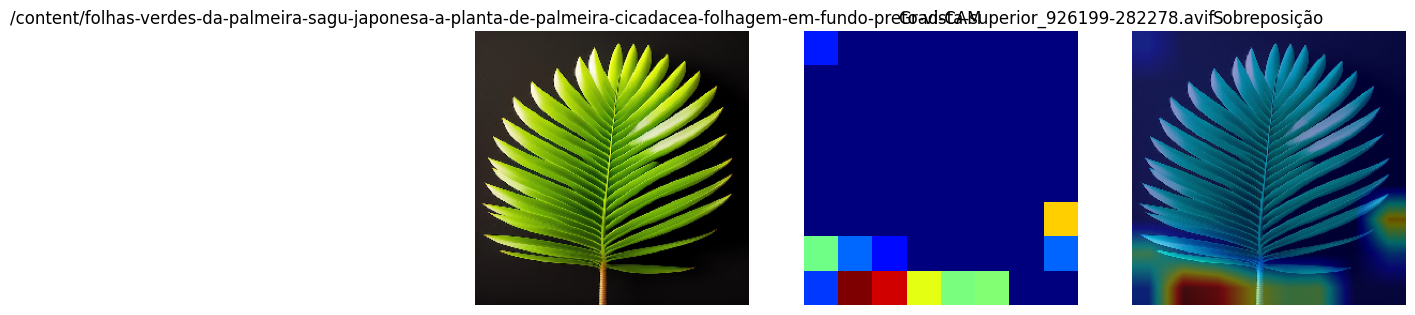

In [ ]:
# Processa para a sobreposição visual
img_uint8 = np.uint8(255 * img_array)
heatmap_resized = cv2.resize(heatmap, (img_uint8.shape[1], img_uint8.shape[0]))
heatmap_colored = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(heatmap_colored, cv2.COLORMAP_JET)
superimposed_img = cv2.addWeighted(img_uint8, 0.6, heatmap_colored, 0.4, 0)

# Plota os 3 resultados lado a lado corretamente
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_array)
plt.title("/content/folhas-verdes-da-palmeira-sagu-japonesa-a-planta-de-palmeira-cicadacea-folhagem-em-fundo-preto-vista-superior_926199-282278.avif")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap='jet')
plt.title("Grad-CAM")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
plt.title("Sobreposição")
plt.axis('off')

plt.show()

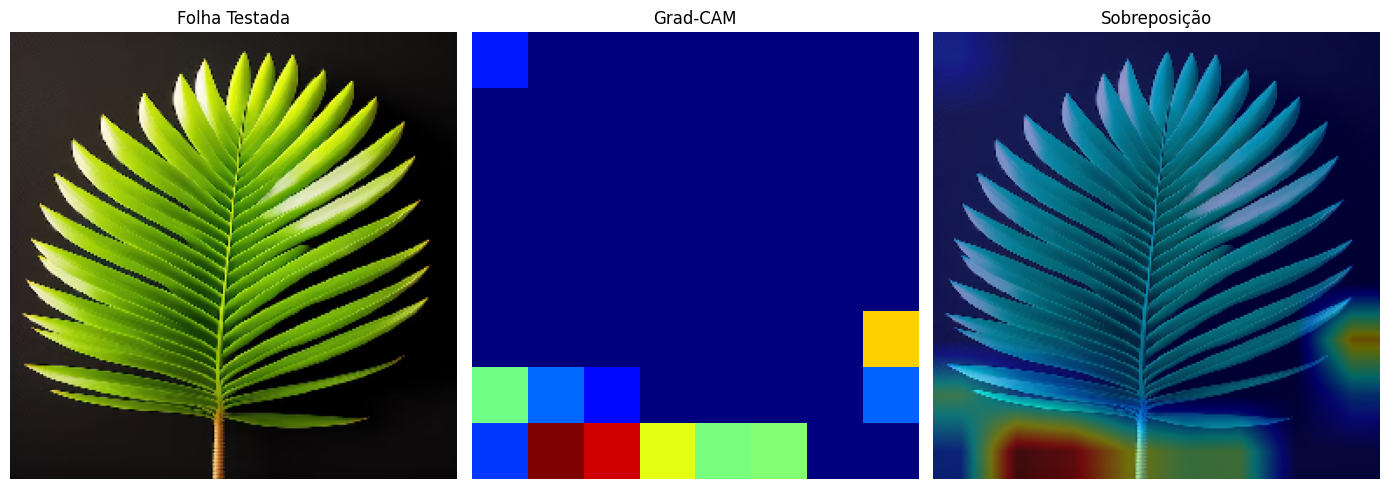

In [ ]:
# Plota os 3 resultados com títulos limpos
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_array)
plt.title("Folha Testada") # Título limpo sem o caminho gigante
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap='jet')
plt.title("Grad-CAM")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
plt.title("Sobreposição")
plt.axis('off')

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
Classe prevista pelo modelo (índice): 2


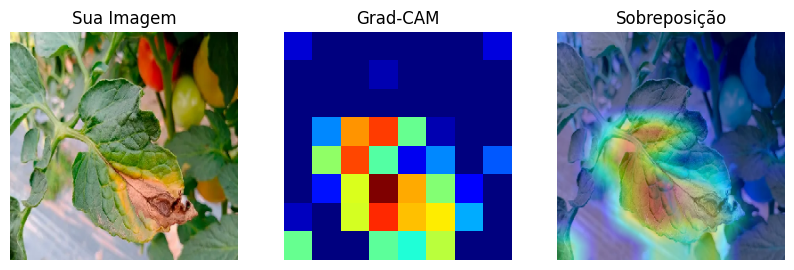

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array

# 1. Carrega a sua imagem redimensionando para o tamanho que o modelo espera (256x256)
img_path = '/content/IMAGEM_3_tomate-como-acabar-com-as-manchas-e-a-requeima-na-cultura.webp' # Coloque o caminho exato da imagem enviada
img_loaded = load_img(img_path, target_size=(256, 256))

# 2. Converte para array e normaliza
img_array = img_to_array(img_loaded) / 255.0
img_array_expanded = np.expand_dims(img_array, axis=0)

# 3. Faz a previsão da classe e gera o Grad-CAM
preds = model.predict(img_array_expanded)
pred_class = np.argmax(preds[0])
print(f"Classe prevista pelo modelo (índice): {pred_class}")

heatmap = make_gradcam_heatmap_fixed(img_array_expanded, model, conv_base, "conv5_block16_concat")

# 4. Plota o resultado
img_uint8 = np.uint8(255 * img_array)
heatmap_resized = cv2.resize(heatmap, (img_uint8.shape[1], img_uint8.shape[0]))
heatmap_colored = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(heatmap_colored, cv2.COLORMAP_JET)
superimposed_img = cv2.addWeighted(img_uint8, 0.6, heatmap_colored, 0.4, 0)

plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.imshow(img_array)
plt.title("Sua Imagem")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap='jet')
plt.title("Grad-CAM")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
plt.title("Sobreposição")
plt.axis('off')
plt.show()

In [ ]:
from tensorflow.keras.utils import load_img, img_to_array

# 1. Carrega a sua imagem redimensionando para o tamanho que o modelo espera (256x256)
img_path = '"C:\Users\user\Downloads\Folhas-de-tomateiro-amarelas-concentricas-e-sinais-de-acaros-na-face-inferior-da-folha.webp"' # Coloque o caminho exato da imagem enviada
img_loaded = load_img(img_path, target_size=(256, 256))

# 2. Converte para array e normaliza
img_array = img_to_array(img_loaded) / 255.0
img_array_expanded = np.expand_dims(img_array, axis=0)

# 3. Faz a previsão da classe e gera o Grad-CAM
preds = model.predict(img_array_expanded)
pred_class = np.argmax(preds[0])
print(f"Classe prevista pelo modelo (índice): {pred_class}")

heatmap = make_gradcam_heatmap_fixed(img_array_expanded, model, conv_base, "conv5_block16_concat")

# 4. Plota o resultado
img_uint8 = np.uint8(255 * img_array)
heatmap_resized = cv2.resize(heatmap, (img_uint8.shape[1], img_uint8.shape[0]))
heatmap_colored = np.uint8(255 * heatmap_resized)
heatmap_colored = cv2.applyColorMap(heatmap_colored, cv2.COLORMAP_JET)
superimposed_img = cv2.addWeighted(img_uint8, 0.6, heatmap_colored, 0.4, 0)

plt.figure(figsize=(10, 4))
plt.subplot(1, 3, 1)
plt.imshow(img_array)
plt.title("Sua Imagem")
plt.axis('off')

SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 3-4: truncated \UXXXXXXXX escape (1089236971.py, line 4)